# **🔗Imports**

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.manifold import TSNE
from PIL import Image
from torchvision import transforms

Connect to Google Drive

In [4]:
from google.colab import drive

drive.mount('/gdrive')
%cd /gdrive/My Drive/Polimi_VAE/datasets

Mounted at /gdrive
/gdrive/My Drive/Polimi_VAE/datasets


# **⚙️Hyperparameters + Device**

In [5]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 256
LATENT_DIM = 32
RIESZ_S = 2.0
LR = 1e-3
EPOCHS = 50
HIDDEN_DIM = 400


# **📄Dataset**

In [6]:
dataset = "bloodmnist.npz"   # <- datasets path

data = np.load(dataset)

train_images = data["train_images"]
train_labels = data["train_labels"]
val_images   = data["val_images"]
val_labels   = data["val_labels"]
test_images  = data["test_images"]
test_labels  = data["test_labels"]


transform_blood = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

class BloodMNISTDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = self.labels[idx]

        img = Image.fromarray(img.astype(np.uint8))

        if self.transform:
            img = self.transform(img)

        label = torch.tensor(label, dtype=torch.long).squeeze()
        return img, label

train_dataset = BloodMNISTDataset(train_images, train_labels, transform=transform_blood)
val_dataset   = BloodMNISTDataset(val_images, val_labels, transform=transform_blood)
test_dataset  = BloodMNISTDataset(test_images, test_labels, transform=transform_blood)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=10,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

NUM_CLASSES = len(np.unique(train_labels))

print("DEVICE:", DEVICE)
print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))
print("NUM_CLASSES:", NUM_CLASSES)
print("Sample image shape:", train_dataset[0][0].shape)   #  [1, 28, 28]
print("Sample label:", train_dataset[0][1])



DEVICE: cpu
Train: 11959
Val: 1712
Test: 3421
NUM_CLASSES: 8
Sample image shape: torch.Size([1, 28, 28])
Sample label: tensor(7)


# **📍</> Standard VAE**

In [7]:
# --- 1. Definizione Modello Standard VAE ---
class StandardVAE(nn.Module):
    def __init__(self):
        super(StandardVAE, self).__init__()

        # Encoder
        self.fc1 = nn.Linear(784, HIDDEN_DIM)

        # Invece di Mu e Scale, qui abbiamo Mu e Log-Varianza (standard VAE)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc_logvar = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, 784)

    def encode(self, x):
        h = F.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            # Calcoliamo la deviazione standard: std = exp(0.5 * log_var)
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        # Ritorniamo anche mu e logvar per calcolare la Loss KL
        return recon, z, mu, logvar

# --- 2. Loss Function (ELBO) ---
def loss_function(recon_x, x, mu, logvar):
    # A. Reconstruction Loss (MSE)
    # reduction='sum' è importante per bilanciare la KL Divergence
    MSE = F.mse_loss(recon_x, x, reduction='sum')

    # B. KL Divergence
    # Misura quanto la distribuzione appresa (mu, logvar) differisce da una Normale(0, 1)
    # Formula analitica per due gaussiane
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return MSE + KLD

# --- 3. Training Loop ---
def train_standard_vae():
    print(f"Start Training Standard VAE on {DEVICE}...")

    # Caricamento Dati

    model = StandardVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()

    for epoch in range(EPOCHS):
        total_loss = 0

        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(DEVICE).view(-1, 784)

            optimizer.zero_grad()

            # Forward
            recon, z, mu, logvar = model(data)

            # Loss
            loss = loss_function(recon, data, mu, logvar)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Log
        avg_loss = total_loss / len(train_loader.dataset)
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss (ELBO): {avg_loss:.4f}")

    print("Training completato.")
    return model

# --- Esecuzione ---

model_v = train_standard_vae()


Start Training Standard VAE on cpu...


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 1/50 | Loss (ELBO): 25.3940
Epoch 2/50 | Loss (ELBO): 17.3769
Epoch 3/50 | Loss (ELBO): 15.9731
Epoch 4/50 | Loss (ELBO): 15.5119
Epoch 5/50 | Loss (ELBO): 15.0907
Epoch 6/50 | Loss (ELBO): 14.7175
Epoch 7/50 | Loss (ELBO): 14.5494
Epoch 8/50 | Loss (ELBO): 14.3822
Epoch 9/50 | Loss (ELBO): 14.2780
Epoch 10/50 | Loss (ELBO): 14.2046
Epoch 11/50 | Loss (ELBO): 14.1658
Epoch 12/50 | Loss (ELBO): 14.0985
Epoch 13/50 | Loss (ELBO): 14.0626
Epoch 14/50 | Loss (ELBO): 13.9977
Epoch 15/50 | Loss (ELBO): 13.9199
Epoch 16/50 | Loss (ELBO): 13.8499
Epoch 17/50 | Loss (ELBO): 13.8126
Epoch 18/50 | Loss (ELBO): 13.7308
Epoch 19/50 | Loss (ELBO): 13.6718
Epoch 20/50 | Loss (ELBO): 13.6466
Epoch 21/50 | Loss (ELBO): 13.6026
Epoch 22/50 | Loss (ELBO): 13.5682
Epoch 23/50 | Loss (ELBO): 13.5042
Epoch 24/50 | Loss (ELBO): 13.5082
Epoch 25/50 | Loss (ELBO): 13.5061
Epoch 26/50 | Loss (ELBO): 13.4668
Epoch 27/50 | Loss (ELBO): 13.4578
Epoch 28/50 | Loss (ELBO): 13.4561
Epoch 29/50 | Loss (ELBO): 13

# **📍</> Geodesic Spherical VAE**

In [8]:
# --- 1. Loss: Riesz s-kernel Energy ---
def riesz_energy_loss(z):
    dists = torch.pdist(z, p=2)
    energy = 1.0 / (dists.pow(RIESZ_S) + 1e-6)
    return energy.mean()

# --- 2. Modello Autoencoder Sferico (Geodesico) ---
class GeodesicSphericalVAE(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.fc1 = nn.Linear(784, HIDDEN_DIM)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)


        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, 784)

    def encode(self, x):
        h = F.relu(self.fc1(x))

        # 1. Mu deve stare sulla sfera
        mu = F.normalize(self.fc_mu(h), p=2, dim=1)

        # 2. Alpha: limitato a ~45 gradi (1.57 / 2 = 0.785 rad)
        alpha = 0.3
        return mu, alpha

    def reparameterize(self, mu, alpha):
        if self.training:
            # 1. Generiamo una direzione casuale 'v'
            v = torch.randn_like(mu)

            # 2. Rendiamo v perpendicolare a mu (Gram-Schmidt)
            v_orth = v - (v * mu).sum(dim=1, keepdim=True) * mu
            v_tangent = F.normalize(v_orth, p=2, dim=1)

            # 3. Scegliamo quanto spostarci (theta) tra 0 e alpha
            theta = alpha * torch.rand(mu.size(0), 1, device=mu.device)

            # 4. Rotazione (Rodrigues semplificato)
            z = mu * torch.cos(theta) + v_tangent * torch.sin(theta)
            return z
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, alpha = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu, alpha)
        recon = self.decode(z)
        return recon, z

# --- 3. Training Loop ---
def main():
    print(f"Esecuzione su: {DEVICE} con MNIST")


    model = GeodesicSphericalVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()
    for epoch in range(EPOCHS):
        total_rec = 0
        total_riesz = 0

        # Warm-up lineare
        beta = 0.05 * epoch

        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(DEVICE).view(-1, 784)
            optimizer.zero_grad()

            # Otteniamo anche alpha dall'output del modello
            recon, z = model(data)

            # Loss A: Ricostruzione
            loss_recon = F.mse_loss(recon, data, reduction='sum') / BATCH_SIZE

            # Loss B: Riesz Energy
            loss_riesz = riesz_energy_loss(z)

            loss = loss_recon + (beta * loss_riesz)

            loss.backward()
            optimizer.step()

            total_rec += loss_recon.item()
            total_riesz += loss_riesz.item()

            # Accumuliamo la media di alpha del batch corrente

        # Calcolo medie per epoca
        avg_rec = total_rec / len(train_loader)
        avg_riesz = total_riesz / len(train_loader)

        print(f"Epoch {epoch+1}/{EPOCHS} | Recon: {avg_rec:.2f} | Riesz: {avg_riesz:.4f} | Beta: {beta:.2f}")

    return model


model_s = main()

Esecuzione su: cpu con MNIST
Epoch 1/50 | Recon: 30.46 | Riesz: 60.2387 | Beta: 0.00
Epoch 2/50 | Recon: 16.84 | Riesz: 21.4286 | Beta: 0.05
Epoch 3/50 | Recon: 11.89 | Riesz: 3.2723 | Beta: 0.10
Epoch 4/50 | Recon: 10.60 | Riesz: 1.8500 | Beta: 0.15
Epoch 5/50 | Recon: 9.95 | Riesz: 1.3594 | Beta: 0.20
Epoch 6/50 | Recon: 9.12 | Riesz: 1.0089 | Beta: 0.25
Epoch 7/50 | Recon: 8.53 | Riesz: 0.8789 | Beta: 0.30
Epoch 8/50 | Recon: 8.13 | Riesz: 0.8211 | Beta: 0.35
Epoch 9/50 | Recon: 7.84 | Riesz: 0.7675 | Beta: 0.40
Epoch 10/50 | Recon: 7.61 | Riesz: 0.7264 | Beta: 0.45
Epoch 11/50 | Recon: 7.38 | Riesz: 0.6996 | Beta: 0.50
Epoch 12/50 | Recon: 7.16 | Riesz: 0.6690 | Beta: 0.55
Epoch 13/50 | Recon: 6.89 | Riesz: 0.6554 | Beta: 0.60
Epoch 14/50 | Recon: 6.67 | Riesz: 0.6330 | Beta: 0.65
Epoch 15/50 | Recon: 6.39 | Riesz: 0.6186 | Beta: 0.70
Epoch 16/50 | Recon: 6.25 | Riesz: 0.6067 | Beta: 0.75
Epoch 17/50 | Recon: 6.06 | Riesz: 0.6045 | Beta: 0.80
Epoch 18/50 | Recon: 6.06 | Riesz: 0.60

# **📊Visual comparison of reconstructions**

Generazione confronto tra i due modelli...


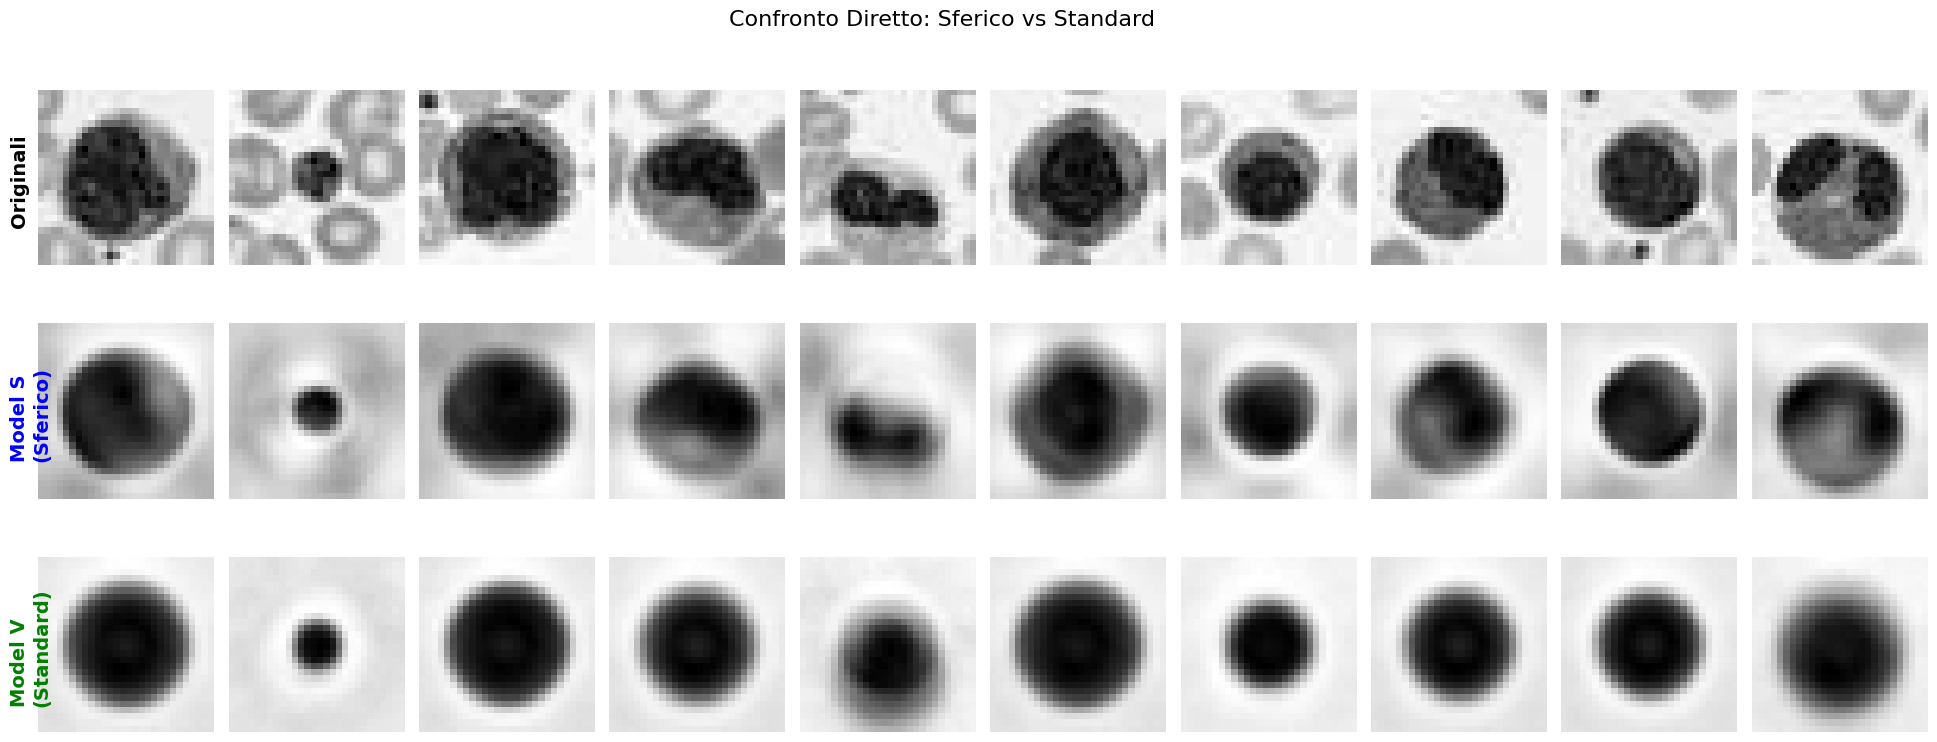

In [9]:
def visualizza_confronto_doppio(model_s, model_v, device, n_images=10):
    """
    Confronta visivamente le ricostruzioni di due modelli diversi (Sferico vs VAE).
    Riga 1: Immagini originali
    Riga 2: Ricostruzione Model S (Sferico)
    Riga 3: Ricostruzione Model V (Standard)
    """
    print("Generazione confronto tra i due modelli...")

    # 1. Carichiamo dati casuali dal test set


    # Prendiamo un batch
    data, _ = next(iter(test_loader))
    data = data.to(device)

    # 2. Inferenza
    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        # --- Model S (Sferico) ---
        # Usa *rest per ignorare z, angoli, ecc.
        recon_s, *rest = model_s(data)

        # --- Model V (Standard) ---
        # Usa *rest per ignorare z, mu, logvar
        recon_v, *rest = model_v(data)

    # Portiamo su CPU
    data = data.cpu()
    recon_s = recon_s.cpu()
    recon_v = recon_v.cpu()

    # 3. Plotting (3 Righe)
    fig, axes = plt.subplots(3, n_images, figsize=(20, 8))

    for i in range(n_images):
        # --- Riga 1: Originale ---
        axes[0, i].imshow(data[i].reshape(28, 28), cmap='gray')
        axes[0, i].axis('off')

        # --- Riga 2: Model S ---
        axes[1, i].imshow(recon_s[i].reshape(28, 28), cmap='gray')
        axes[1, i].axis('off')

        # --- Riga 3: Model V ---
        axes[2, i].imshow(recon_v[i].reshape(28, 28), cmap='gray')
        axes[2, i].axis('off')

    # Titoli descrittivi a sinistra
    axes[0, 0].text(-5, 14, "Originali", fontsize=14, rotation=90, verticalalignment='center', fontweight='bold')
    axes[1, 0].text(-5, 14, "Model S\n(Sferico)", fontsize=14, rotation=90, verticalalignment='center', fontweight='bold', color='blue')
    axes[2, 0].text(-5, 14, "Model V\n(Standard)", fontsize=14, rotation=90, verticalalignment='center', fontweight='bold', color='green')

    plt.suptitle("Confronto Diretto: Sferico vs Standard", fontsize=16)
    plt.tight_layout(rect=[0.03, 0, 1, 1]) # Lascia spazio a sinistra per i testi
    plt.show()

visualizza_confronto_doppio(model_s, model_v, DEVICE, 10)

Generazione di 10 nuove immagini da rumore casuale (Dim=32)...


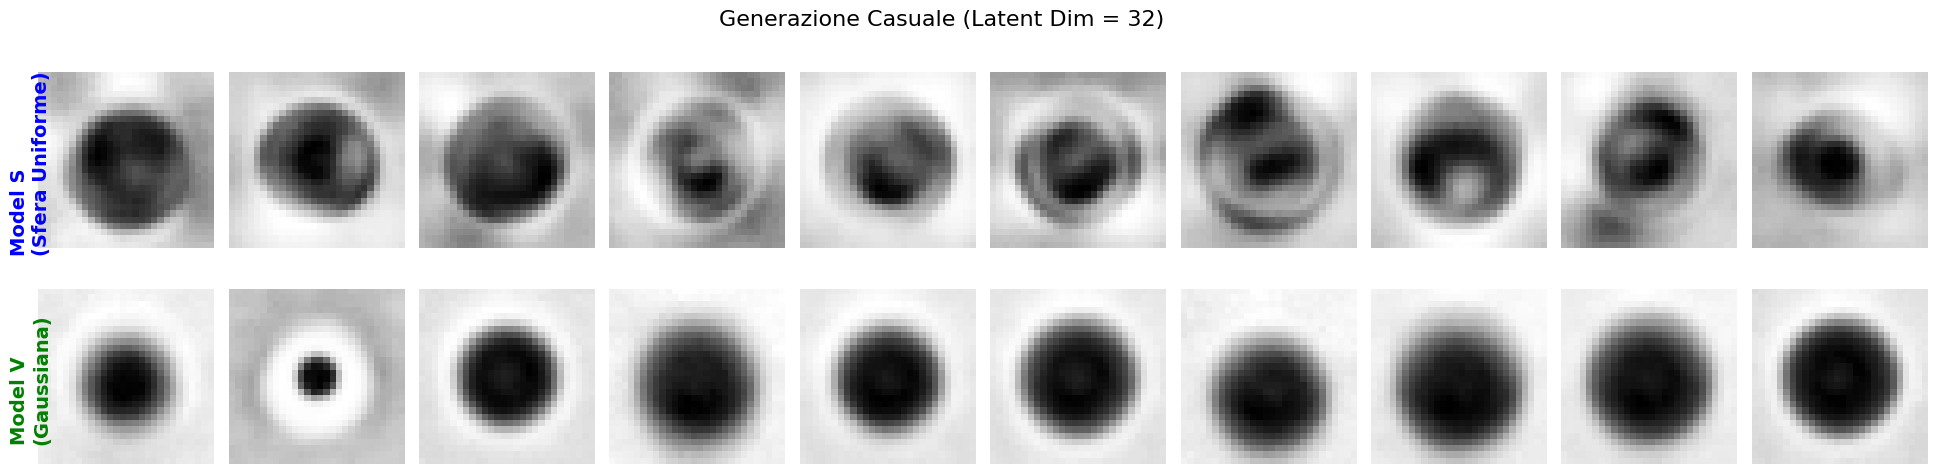

In [10]:
def visualizza_generazione_casuale(model_s, model_v, device, latent_dim, n_images=10):
    """
    Genera immagini da rumore casuale (Latent Space Sampling).
    - Model S: Campiona uniformemente dalla superficie della sfera.
    - Model V: Campiona da una distribuzione Normale (Gaussiana).
    """
    print(f"Generazione di {n_images} nuove immagini da rumore casuale (Dim={latent_dim})...")

    model_s.eval()
    model_v.eval()

    # 1. Generazione Vettori Latenti (Z)

    # A. Per il Sferico: Gaussiana -> Normalizzazione L2
    # Questo garantisce una distribuzione UNIFORME sulla superficie della sfera
    z_s_raw = torch.randn(n_images, latent_dim).to(device)
    z_s = F.normalize(z_s_raw, p=2, dim=1)

    # B. Per il VAE Standard: Gaussiana Pura (N(0,1))
    z_v = torch.randn(n_images, latent_dim).to(device)

    # 2. Decoding (Generazione Immagini)
    with torch.no_grad():
        # Usiamo direttamente il metodo .decode() definito nelle classi
        gen_s = model_s.decode(z_s).cpu()
        gen_v = model_v.decode(z_v).cpu()

    # 3. Plotting
    fig, axes = plt.subplots(2, n_images, figsize=(20, 5))

    for i in range(n_images):
        # --- Riga 1: Generazione Sferica ---
        axes[0, i].imshow(gen_s[i].reshape(28, 28), cmap='gray')
        axes[0, i].axis('off')

        # --- Riga 2: Generazione Gaussiana ---
        axes[1, i].imshow(gen_v[i].reshape(28, 28), cmap='gray')
        axes[1, i].axis('off')

    # Titoli descrittivi
    axes[0, 0].text(-5, 14, "Model S\n(Sfera Uniforme)", fontsize=14, rotation=90, verticalalignment='center', fontweight='bold', color='blue')
    axes[1, 0].text(-5, 14, "Model V\n(Gaussiana)", fontsize=14, rotation=90, verticalalignment='center', fontweight='bold', color='green')

    plt.suptitle(f"Generazione Casuale (Latent Dim = {latent_dim})", fontsize=16)
    plt.tight_layout(rect=[0.03, 0, 1, 1])
    plt.show()

# Esempio di utilizzo:
# Assicurati di passare la variabile LATENT_DIM corretta

visualizza_generazione_casuale(model_s, model_v, DEVICE, LATENT_DIM)

Estrazione vettori latenti dal Training Set...
Calcolo PCA su 3421 punti...


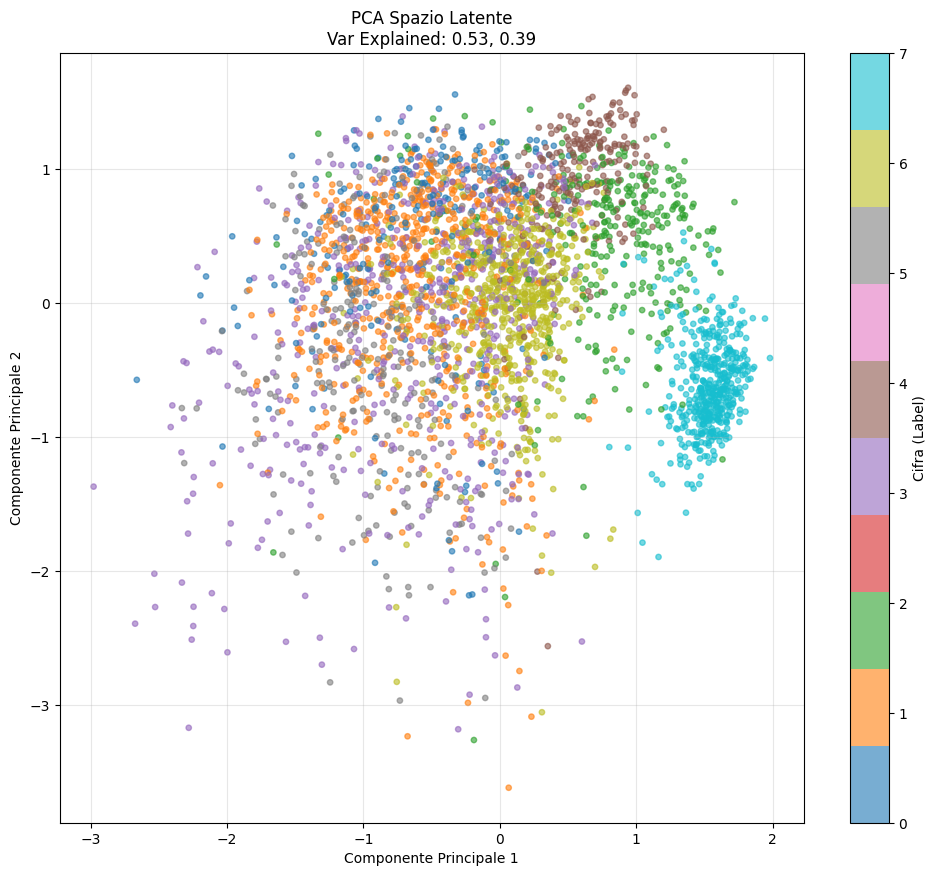

In [11]:
def visualizza_pca_training(model, device, num_points=5000):
    print("Estrazione vettori latenti dal Training Set...")
    model.eval()

    loader = test_loader

    all_z = []
    all_labels = []

    # Raccogliamo i dati
    count = 0
    with torch.no_grad():
        for data, labels in loader:
            data = data.to(device).view(-1, 784)

            # --- MODIFICA ROBUSTA ---
            # model.encode può restituire (mu, scale) oppure (mu, logvar)
            # Usando *rest prendiamo sempre il primo elemento (mu) e ignoriamo il resto
            mu, *rest = model.encode(data)

            all_z.append(mu.cpu().numpy())
            all_labels.append(labels.numpy())

            count += len(labels)
            if count >= num_points:
                break

    # Convertiamo in array numpy unici
    X = np.concatenate(all_z)[:num_points]
    y = np.concatenate(all_labels)[:num_points]

    print(f"Calcolo PCA su {X.shape[0]} punti...")

    # Appliciamo PCA per ridurre a 2 dimensioni
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    # --- Plotting ---
    plt.figure(figsize=(12, 10))

    # Scatter plot con colori diversi per ogni cifra (0-9)
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10', alpha=0.6, s=15)

    # Legenda e abbellimenti
    plt.colorbar(scatter, ticks=range(10), label='Cifra (Label)')

    # Titolo dinamico
    # Se la varianza spiegata è alta, la PCA è una buona rappresentazione
    var_ratio = pca.explained_variance_ratio_
    plt.title(f'PCA Spazio Latente\nVar Explained: {var_ratio[0]:.2f}, {var_ratio[1]:.2f}')

    plt.xlabel('Componente Principale 1')
    plt.ylabel('Componente Principale 2')
    plt.grid(True, alpha=0.3)

    plt.show()


visualizza_pca_training(model_v, DEVICE)

Confronto Interpolazione: Slerp (Sferico) vs Lerp (VAE)...


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


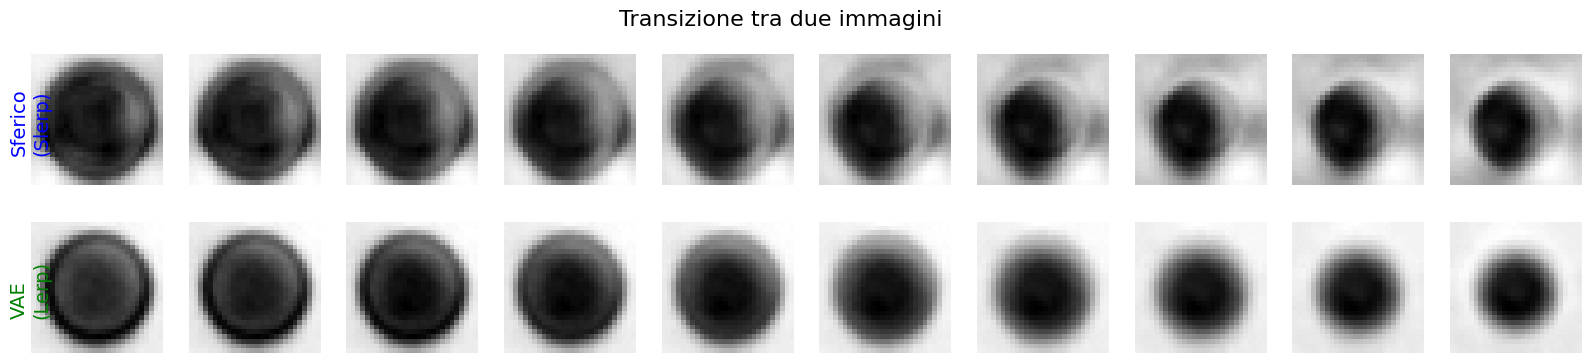

In [12]:
import numpy as np

def slerp(val, low, high):
    """Spherical Linear Interpolation"""
    omega = torch.acos(torch.clamp(torch.sum(low/torch.norm(low) * high/torch.norm(high)), -1, 1))
    so = torch.sin(omega)
    if so == 0:
        return (1.0-val) * low + val * high # Fallback lineare se sono paralleli
    return torch.sin((1.0-val)*omega) / so * low + torch.sin(val*omega) / so * high

def lerp(val, low, high):
    """Linear Interpolation (Standard)"""
    return (1.0 - val) * low + val * high

def visualizza_interpolazione(model_s, model_v, device, steps=10):
    print("Confronto Interpolazione: Slerp (Sferico) vs Lerp (VAE)...")

    # Prendiamo due immagini dal test set: Start e End
    loader = test_loader
    images, _ = next(iter(loader))
    img1, img2 = images[0].to(device), images[1].to(device)

    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        # Encoding
        # Nota: model_s restituisce (recon, z, ...). Prendiamo z [index 1]
        z1_s = model_s.encode(img1.view(-1, 784))[0] # Prende mu
        z2_s = model_s.encode(img2.view(-1, 784))[0]

        z1_v = model_v.encode(img1.view(-1, 784))[0] # Prende mu
        z2_v = model_v.encode(img2.view(-1, 784))[0]

        # Generazione step intermedi
        ratios = np.linspace(0, 1, steps)

        pics_s = []
        pics_v = []

        for r in ratios:
            # Sferico -> SLERP
            z_interp_s = slerp(r, z1_s, z2_s)
            pics_s.append(model_s.decode(z_interp_s).cpu().view(28, 28))

            # VAE -> LERP
            z_interp_v = lerp(r, z1_v, z2_v)
            pics_v.append(model_v.decode(z_interp_v).cpu().view(28, 28))

    # Plotting
    fig, axes = plt.subplots(2, steps, figsize=(20, 4))

    for i in range(steps):
        axes[0, i].imshow(pics_s[i], cmap='gray')
        axes[0, i].axis('off')
        axes[1, i].imshow(pics_v[i], cmap='gray')
        axes[1, i].axis('off')

    axes[0, 0].text(-5, 14, "Sferico\n(Slerp)", fontsize=14, rotation=90, verticalalignment='center', color='blue')
    axes[1, 0].text(-5, 14, "VAE\n(Lerp)", fontsize=14, rotation=90, verticalalignment='center', color='green')

    plt.suptitle("Transizione tra due immagini", fontsize=16)
    plt.show()

# Esegui (dopo aver addestrato su FashionMNIST per risultati migliori)
visualizza_interpolazione(model_s, model_v, DEVICE)

Calcolo dei centroidi (immagini medie) per Model G e Model V...


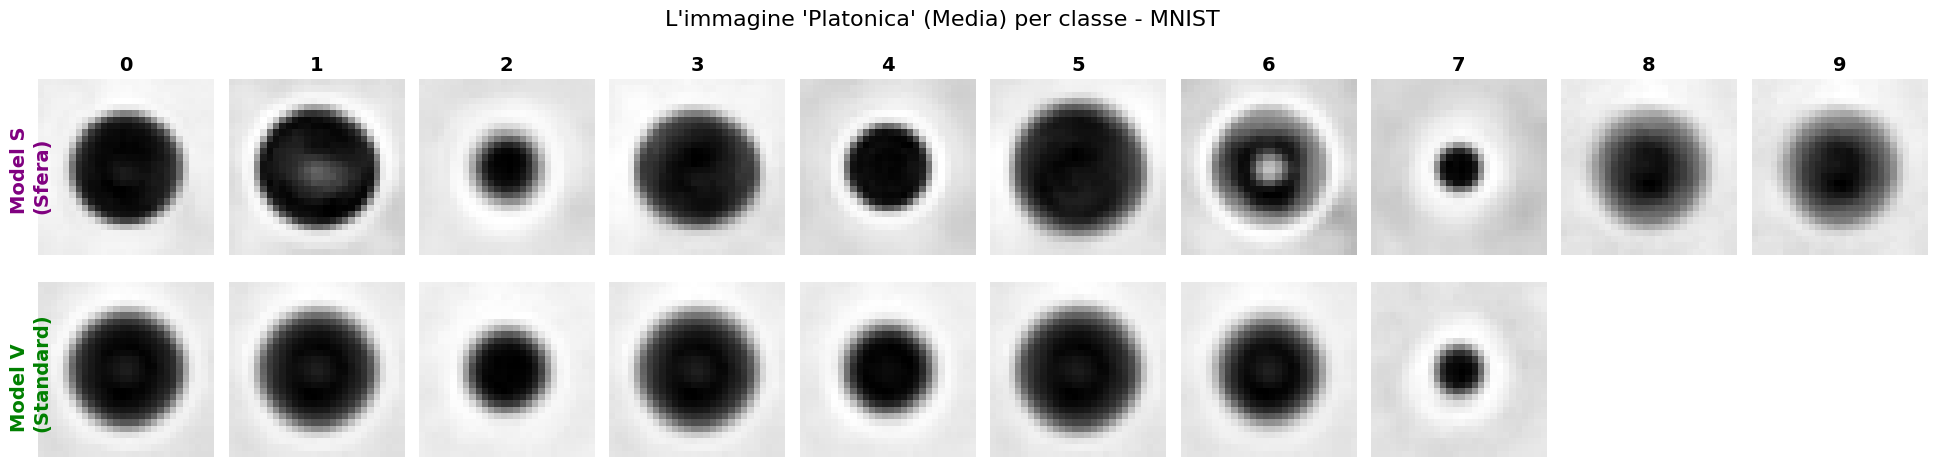

In [13]:
def visualizza_centroidi_gv(model_g, model_v, device, latent_dim):
    print("Calcolo dei centroidi (immagini medie) per Model G e Model V...")

    # Carichiamo MNIST (Test set)

    # Batch size grande per velocizzare
    loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

    model_g.eval()
    model_v.eval()

    # --- 1. Inizializzazione Accumulatori ---
    # Teniamo traccia della somma dei vettori z per ogni classe (0-9)
    sum_z_g = torch.zeros(10, latent_dim).to(device)
    sum_z_v = torch.zeros(10, latent_dim).to(device)

    # Conta quante volte appare ogni cifra per fare la media aritmetica
    class_counts = torch.zeros(10).to(device)

    # --- 2. Accumulo Vettori Latenti ---
    with torch.no_grad():
        for data, labels in loader:
            data = data.to(device)
            labels = labels.to(device)

            # Encoding
            # Model G: restituisce (mu, alpha) -> prendiamo mu [0]
            z_g, *rest = model_g.encode(data.view(-1, 784))

            # Model V: restituisce (mu, logvar) -> prendiamo mu [0] o (recon, z, mu, logvar)
            # Per sicurezza usiamo encode se disponibile, che restituisce i parametri della distribuzione
            z_v, *rest = model_v.encode(data.view(-1, 784))

            # Somma accumulata per indice di classe
            sum_z_g.index_add_(0, labels, z_g)
            sum_z_v.index_add_(0, labels, z_v)

            # Aggiornamento conteggi
            class_counts.index_add_(0, labels, torch.ones_like(labels, dtype=torch.float))

    # --- 3. Calcolo Medie e Generazione Immagini ---

    # A. Media Model V (Euclideo) -> Somma / Conteggio
    mean_z_v = sum_z_v / class_counts.unsqueeze(1)
    imgs_v = model_v.decode(mean_z_v).cpu()

    # B. Media Model G (Sferico) -> Somma normalizzata
    # Sulla sfera, la "media" è la direzione risultante dalla somma dei vettori
    mean_z_g = torch.nn.functional.normalize(sum_z_g, p=2, dim=1)
    imgs_g = model_g.decode(mean_z_g).cpu()

    # --- 4. Plotting (2 Righe) ---
    fig, axes = plt.subplots(2, 10, figsize=(20, 5))

    digits = range(10)

    for i in digits:
        # Riga 1: Model G (Geodesico)
        axes[0, i].imshow(imgs_g[i].reshape(28, 28).detach().numpy(), cmap='gray')
        axes[0, i].axis('off')

        # Titolo colonna (solo prima riga)
        axes[0, i].set_title(str(i), fontsize=14, fontweight='bold')

        # Riga 2: Model V (Standard)
        axes[1, i].imshow(imgs_v[i].reshape(28, 28).detach().numpy(), cmap='gray')
        axes[1, i].axis('off')

    # Etichette descrittive a sinistra
    axes[0, 0].text(-5, 14, "Model S\n(Sfera)", fontsize=14, rotation=90, va='center', color='purple', fontweight='bold')
    axes[1, 0].text(-5, 14, "Model V\n(Standard)", fontsize=14, rotation=90, va='center', color='green', fontweight='bold')

    plt.suptitle(f"L'immagine 'Platonica' (Media) per classe - MNIST", fontsize=16)
    plt.tight_layout(rect=[0.03, 0, 1, 1])
    plt.show()

# Esegui la funzione
visualizza_centroidi_gv(model_s, model_v, DEVICE, LATENT_DIM)

Computing t-SNE with cosine metric...


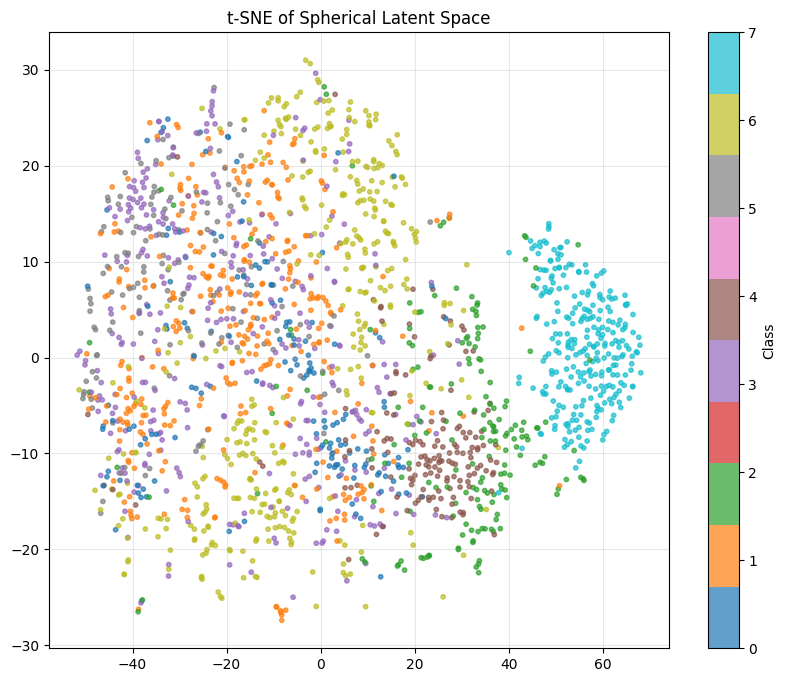

In [14]:
def visualizza_tsne_sferico(model, device, num_points=2000):
    print("Computing t-SNE with cosine metric...")

    model.eval()
    loader = DataLoader(test_dataset, batch_size=128, shuffle=True)

    all_z = []
    all_labels = []
    count = 0

    with torch.no_grad():
        for data, labels in loader:
            data = data.to(device).view(-1, 784)
            z, *rest = model.encode(data)

            all_z.append(z.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

            count += len(labels)
            if count >= num_points:
                break

    X = np.concatenate(all_z, axis=0)[:num_points]
    y = np.concatenate(all_labels, axis=0)[:num_points]

    tsne = TSNE(n_components=2, metric='cosine', init='pca', learning_rate='auto', random_state=42)
    X_embedded = tsne.fit_transform(X)

    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y, cmap='tab10', s=10, alpha=0.7)
    plt.colorbar(scatter, ticks=range(NUM_CLASSES), label='Class')
    plt.title("t-SNE of Spherical Latent Space")
    plt.grid(True, alpha=0.3)
    plt.show()

visualizza_tsne_sferico(model_s, DEVICE, 2000)


--- Sharpness comparison on 1000 generated samples ---
Real images - Mean sharpness: 0.0442 (+/- 0.0140)
------------------------------
Spherical - Mean sharpness: 0.0306 (+/- 0.0085)
Standard  - Mean sharpness: 0.0299 (+/- 0.0105)
------------------------------


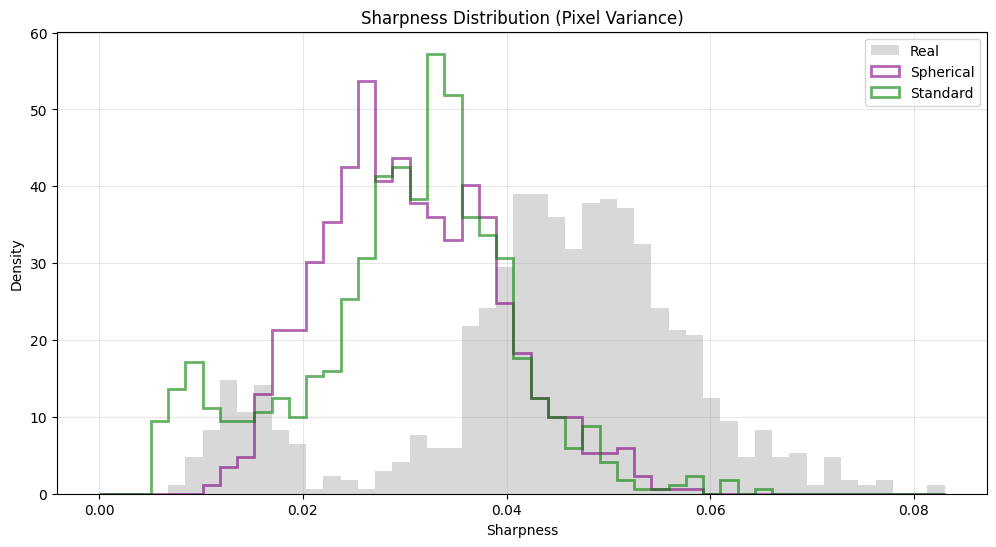

In [15]:
def calcola_statistiche_nitidezza(images_tensor):
    flat_images = images_tensor.view(images_tensor.size(0), -1)
    variances = torch.var(flat_images, dim=1).cpu().numpy()
    return variances

def confronto_quantitativo_generazione(model_g, model_v, device, latent_dim, n_samples=1000):
    print(f"\n--- Sharpness comparison on {n_samples} generated samples ---")

    model_g.eval()
    model_v.eval()

    real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
    real_imgs, _ = next(iter(real_loader))
    var_real = calcola_statistiche_nitidezza(real_imgs)
    print(f"Real images - Mean sharpness: {var_real.mean():.4f} (+/- {var_real.std():.4f})")

    with torch.no_grad():
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        gen_imgs_g = model_g.decode(z_g)
        var_g = calcola_statistiche_nitidezza(gen_imgs_g)

        z_v = torch.randn(n_samples, latent_dim).to(device)
        gen_imgs_v = model_v.decode(z_v)
        var_v = calcola_statistiche_nitidezza(gen_imgs_v)

    print("-" * 30)
    print(f"Spherical - Mean sharpness: {var_g.mean():.4f} (+/- {var_g.std():.4f})")
    print(f"Standard  - Mean sharpness: {var_v.mean():.4f} (+/- {var_v.std():.4f})")
    print("-" * 30)

    plt.figure(figsize=(12, 6))
    bins = np.linspace(0, max(var_real.max(), var_g.max(), var_v.max()), 50)

    plt.hist(var_real, bins=bins, alpha=0.3, color='gray', label='Real', density=True)
    plt.hist(var_g, bins=bins, alpha=0.6, color='purple', label='Spherical', density=True, histtype='step', linewidth=2)
    plt.hist(var_v, bins=bins, alpha=0.6, color='green', label='Standard', density=True, histtype='step', linewidth=2)

    plt.title("Sharpness Distribution (Pixel Variance)")
    plt.xlabel("Sharpness")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

confronto_quantitativo_generazione(model_s, model_v, DEVICE, LATENT_DIM, n_samples=1000)


--- Diversity analysis on 1000 generated samples ---
Real dataset diversity: 5.9638
Spherical diversity: 4.4885
Standard diversity:  3.0631
----------------------------------------
Spherical: 75.3% of real diversity
Standard : 51.4% of real diversity
----------------------------------------


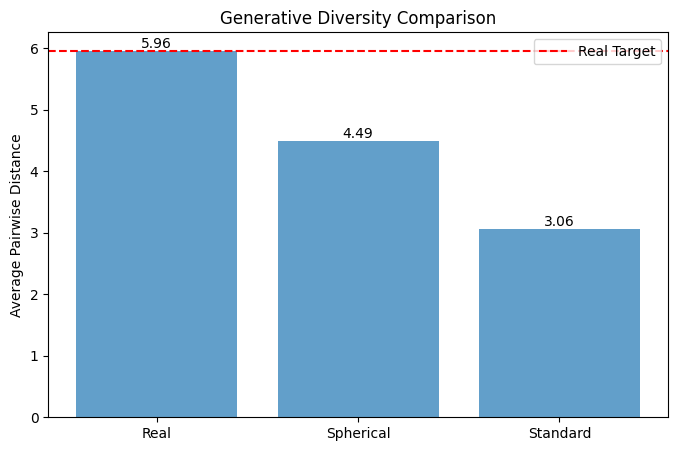

In [16]:
#Diversity statistics
def get_average_pairwise_distance(images_tensor):
    flat = images_tensor.view(images_tensor.size(0), -1)
    dists = torch.cdist(flat, flat, p=2)
    return dists.mean().item()

def confronto_diversita(model_g, model_v, device, latent_dim, n_samples=1000):
    print(f"\n--- Diversity analysis on {n_samples} generated samples ---")

    model_g.eval()
    model_v.eval()

    real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
    real_imgs, _ = next(iter(real_loader))
    real_imgs = real_imgs.to(device)

    diversity_real = get_average_pairwise_distance(real_imgs)
    print(f"Real dataset diversity: {diversity_real:.4f}")

    with torch.no_grad():
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        gen_imgs_g = model_g.decode(z_g)
        diversity_g = get_average_pairwise_distance(gen_imgs_g)

        z_v = torch.randn(n_samples, latent_dim).to(device)
        gen_imgs_v = model_v.decode(z_v)
        diversity_v = get_average_pairwise_distance(gen_imgs_v)

    print(f"Spherical diversity: {diversity_g:.4f}")
    print(f"Standard diversity:  {diversity_v:.4f}")

    perc_g = (diversity_g / diversity_real) * 100
    perc_v = (diversity_v / diversity_real) * 100

    print("-" * 40)
    print(f"Spherical: {perc_g:.1f}% of real diversity")
    print(f"Standard : {perc_v:.1f}% of real diversity")
    print("-" * 40)

    plt.figure(figsize=(8, 5))
    methods = ['Real', 'Spherical', 'Standard']
    values = [diversity_real, diversity_g, diversity_v]

    bars = plt.bar(methods, values, alpha=0.7)
    plt.axhline(y=diversity_real, color='red', linestyle='--', label='Real Target')

    plt.ylabel("Average Pairwise Distance")
    plt.title("Generative Diversity Comparison")
    plt.legend()

    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.2f}", ha='center', va='bottom')

    plt.show()

confronto_diversita(model_s, model_v, DEVICE, LATENT_DIM)


--- Inception-like Score on 2000 generated samples ---
Training classifier for Inception-like score...


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Classifier ready.
Calculating score for spherical model...
Calculating score for standard model...
----------------------------------------
Spherical: 1.9947 +/- 0.0513
Standard : 2.0904 +/- 0.0523
----------------------------------------


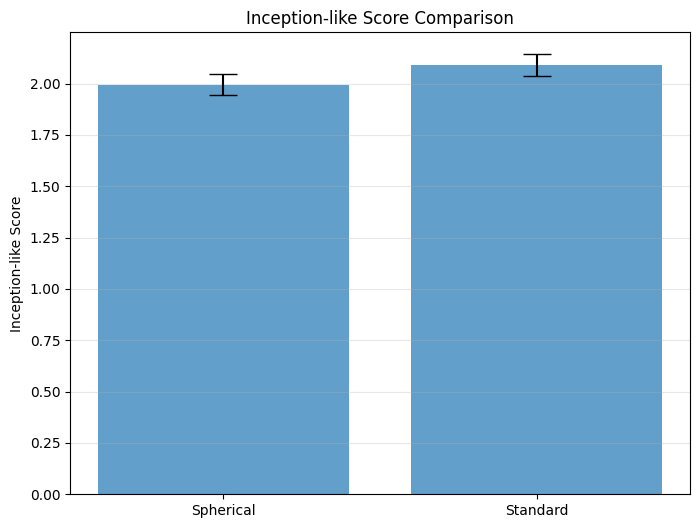

In [17]:
# 14. Classifier for Inception-like score
# =========================
class RobustClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.dropout1 = nn.Dropout(0.25)
        self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)
        x = self.dropout1(x)
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout2(x)
        x = self.fc2(x)
        return F.softmax(x, dim=1)

def train_or_load_classifier(device):
    model = RobustClassifier(NUM_CLASSES).to(device)
    print("Training classifier for Inception-like score...")

    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    model.train()
    for epoch in range(3):
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = F.nll_loss(torch.log(output + 1e-10), target)
            loss.backward()
            optimizer.step()

    model.eval()
    print("Classifier ready.")
    return model

def calculate_inception_score(generated_images, classifier, device, splits=10):
    classifier.eval()
    preds = []

    gen_dataset = torch.utils.data.TensorDataset(generated_images)
    gen_loader = DataLoader(gen_dataset, batch_size=100)

    with torch.no_grad():
        for batch in gen_loader:
            batch_imgs = batch[0].to(device)
            pred = classifier(batch_imgs)
            preds.append(pred.cpu().numpy())

    preds = np.concatenate(preds, axis=0)
    scores = []
    n_part = preds.shape[0] // splits

    for i in range(splits):
        part = preds[i * n_part : (i + 1) * n_part]
        p_y = np.expand_dims(np.mean(part, axis=0), 0)

        kl_div = part * (np.log(part + 1e-16) - np.log(p_y + 1e-16))
        kl_div = np.sum(kl_div, axis=1)
        avg_kl = np.mean(kl_div)

        scores.append(np.exp(avg_kl))

    return np.mean(scores), np.std(scores)

def confronta_inception_score(model_g, model_v, device, latent_dim, n_samples=2000):
    print(f"\n--- Inception-like Score on {n_samples} generated samples ---")

    judge = train_or_load_classifier(device)

    model_g.eval()
    model_v.eval()

    with torch.no_grad():
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        imgs_g = model_g.decode(z_g).view(-1, 1, 28, 28)

        z_v = torch.randn(n_samples, latent_dim).to(device)
        imgs_v = model_v.decode(z_v).view(-1, 1, 28, 28)

    print("Calculating score for spherical model...")
    mean_g, std_g = calculate_inception_score(imgs_g, judge, device)

    print("Calculating score for standard model...")
    mean_v, std_v = calculate_inception_score(imgs_v, judge, device)

    print("-" * 40)
    print(f"Spherical: {mean_g:.4f} +/- {std_g:.4f}")
    print(f"Standard : {mean_v:.4f} +/- {std_v:.4f}")
    print("-" * 40)

    labels = ['Spherical', 'Standard']
    means = [mean_g, mean_v]
    errors = [std_g, std_v]

    plt.figure(figsize=(8, 6))
    plt.bar(labels, means, yerr=errors, capsize=10, alpha=0.7)
    plt.ylabel("Inception-like Score")
    plt.title("Inception-like Score Comparison")
    plt.grid(axis='y', alpha=0.3)
    plt.show()

confronta_inception_score(model_s, model_v, DEVICE, LATENT_DIM)

In [18]:
# =========================
# FID: Fréchet Inception Distance
# =========================
from torchvision.models import inception_v3, Inception_V3_Weights
from scipy.linalg import sqrtm

class InceptionFeatureExtractor(nn.Module):
    """
    Estrae feature dall'InceptionV3 pre-addestrata.
    Usiamo il layer finale prima della classificazione per il calcolo del FID.
    """
    def __init__(self, device):
        super().__init__()

        weights = Inception_V3_Weights.DEFAULT
        self.model = inception_v3(weights=weights, transform_input=False)

        # Rimuove il classificatore finale
        self.model.fc = nn.Identity()
        self.model.eval()
        self.model.to(device)

        self.device = device

    def forward(self, x):
        """
        x: tensor [B, C, H, W] in [0,1]
        Restituisce feature [B, 2048]
        """

        # Se l'immagine è grayscale, replica i canali per ottenere 3 canali
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)

        # Resize a 299x299 per InceptionV3
        x = F.interpolate(x, size=(299, 299), mode='bilinear', align_corners=False)

        # Normalizzazione ImageNet
        mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
        x = (x - mean) / std

        with torch.no_grad():
            feat = self.model(x)

        return feat


def get_real_images_from_loader(loader, n_samples, device):
    """
    Estrae n_samples immagini reali dal DataLoader.
    """
    imgs = []
    collected = 0

    for data, _ in loader:
        imgs.append(data)
        collected += data.size(0)
        if collected >= n_samples:
            break

    imgs = torch.cat(imgs, dim=0)[:n_samples].to(device)
    return imgs


def get_generated_images(model, latent_dim, n_samples, device):
    """
    Genera n_samples immagini da un modello generativo.
    Supporta:
    - modello sferico: campionamento su sfera
    - VAE standard: campionamento gaussiano
    """
    model.eval()

    with torch.no_grad():
        # Caso sferico: se il nome della classe contiene 'spherical' o 'geodesic'
        model_name = model.__class__.__name__.lower()

        if "spherical" in model_name or "geodesic" in model_name:
            z = torch.randn(n_samples, latent_dim, device=device)
            z = F.normalize(z, p=2, dim=1)
        else:
            z = torch.randn(n_samples, latent_dim, device=device)

        imgs = model.decode(z)

        # Se il decoder restituisce immagini flattenate, le rimodella
        if imgs.ndim == 2:
            imgs = imgs.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        imgs = imgs.clamp(0, 1)

    return imgs


def get_activations(images, feature_extractor, batch_size=64):
    """
    Estrae le feature Inception da un insieme di immagini.
    """
    acts = []

    for i in range(0, images.size(0), batch_size):
        batch = images[i:i+batch_size]
        feat = feature_extractor(batch)
        acts.append(feat.cpu().numpy())

    acts = np.concatenate(acts, axis=0)
    return acts


def compute_statistics(activations):
    """
    Calcola media e matrice di covarianza delle feature.
    """
    mu = np.mean(activations, axis=0)
    sigma = np.cov(activations, rowvar=False)
    return mu, sigma


def calculate_fid(mu1, sigma1, mu2, sigma2, eps=1e-6):
    """
    Calcola il Fréchet Inception Distance (FID).
    """
    diff = mu1 - mu2

    # Stabilizzazione numerica
    covmean, _ = sqrtm((sigma1 @ sigma2).astype(np.float64), disp=False)

    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = sqrtm((sigma1 + offset) @ (sigma2 + offset))

    # Se sqrtm restituisce numeri complessi, prende la parte reale
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff @ diff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return float(fid)


def compute_fid_for_model(model, real_loader, latent_dim, n_samples, device, feature_extractor):
    """
    Calcola il FID tra immagini reali e immagini generate da un modello.
    """
    print(f"Estrazione di {n_samples} immagini reali...")
    real_imgs = get_real_images_from_loader(real_loader, n_samples, device)

    print(f"Generazione di {n_samples} immagini sintetiche...")
    fake_imgs = get_generated_images(model, latent_dim, n_samples, device)

    print("Estrazione feature Inception per immagini reali...")
    real_acts = get_activations(real_imgs, feature_extractor)

    print("Estrazione feature Inception per immagini generate...")
    fake_acts = get_activations(fake_imgs, feature_extractor)

    mu_real, sigma_real = compute_statistics(real_acts)
    mu_fake, sigma_fake = compute_statistics(fake_acts)

    fid = calculate_fid(mu_real, sigma_real, mu_fake, sigma_fake)
    return fid


def confronta_fid(model_s, model_v, real_loader, latent_dim, device, n_samples=2000):
    """
    Confronta il FID del modello sferico e del VAE standard.
    """
    print(f"\n--- FID su {n_samples} campioni generati ---")

    feature_extractor = InceptionFeatureExtractor(device)

    print("\nCalcolo FID per il modello sferico...")
    fid_s = compute_fid_for_model(
        model=model_s,
        real_loader=real_loader,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        feature_extractor=feature_extractor
    )

    print("\nCalcolo FID per il VAE standard...")
    fid_v = compute_fid_for_model(
        model=model_v,
        real_loader=real_loader,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        feature_extractor=feature_extractor
    )

    print("-" * 40)
    print(f"FID Modello Sferico : {fid_s:.4f}")
    print(f"FID VAE Standard    : {fid_v:.4f}")
    print("-" * 40)
    print("Nota: un valore FID più basso indica una migliore qualità generativa.")

    labels = ['Sferico', 'Standard']
    values = [fid_s, fid_v]

    plt.figure(figsize=(8, 6))
    bars = plt.bar(labels, values, alpha=0.7)
    plt.ylabel("FID")
    plt.title("Confronto FID tra i due modelli")
    plt.grid(axis='y', alpha=0.3)

    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.2f}",
                 ha='center', va='bottom')

    plt.show()

    return fid_s, fid_v


--- FID su 1000 campioni generati ---
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:01<00:00, 70.4MB/s] 



Calcolo FID per il modello sferico...
Estrazione di 1000 immagini reali...
Generazione di 1000 immagini sintetiche...
Estrazione feature Inception per immagini reali...
Estrazione feature Inception per immagini generate...


/tmp/ipykernel_9875/1552147419.py:127: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = sqrtm((sigma1 @ sigma2).astype(np.float64), disp=False)



Calcolo FID per il VAE standard...
Estrazione di 1000 immagini reali...
Generazione di 1000 immagini sintetiche...
Estrazione feature Inception per immagini reali...
Estrazione feature Inception per immagini generate...
----------------------------------------
FID Modello Sferico : 265.1067
FID VAE Standard    : 299.4428
----------------------------------------
Nota: un valore FID più basso indica una migliore qualità generativa.


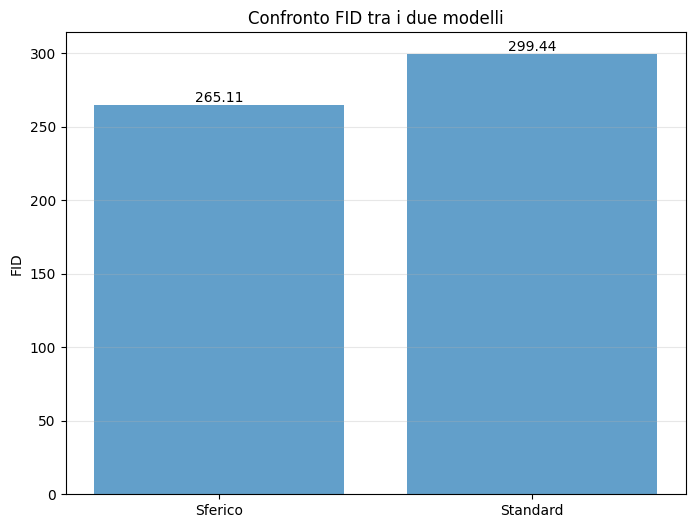

In [19]:
sample_batch, _ = next(iter(test_loader))
IMAGE_SIZE = tuple(sample_batch.shape[2:4])   # (28, 28)
IN_CHANNELS = sample_batch.shape[1]           # 1

fid_s, fid_v = confronta_fid(
    model_s,
    model_v,
    test_loader,
    LATENT_DIM,
    DEVICE,
    n_samples=1000
)